# Longest summer dry spell over Northern Hemisphere mid-latitude land (30–60°N): CMIP6 models

Same box-and-whisker plot as the last figure of `land_histo_dry_consect_NH_plot.ipynb`, with one box per CMIP6 model.

- **Data**: the 30–60°N per-member files written by `cmip6_dry_spell_calc.py`. Only the first member of each model is used (`MEMBERS_PER_MODEL = 1`; lowest r, then i, p, f, e.g. r1i1p1f1, or r2i1p1f1 if r1 does not exist), so every model counts equally. All years of that member are pooled into one box.
- **Land mask**: `sftlf` from `/net/atmos/data/cmip6-ng/sftlf/fx/native`, with land defined as `sftlf > 0`. One mask per model is used for all its members. The historical mask is preferred, otherwise any experiment is used. Each data grid point takes the value of the nearest mask point, so small coordinate differences between files (lat precision, lon convention) don't matter; the printout reports any offset.
- **Models without an sftlf file** (BCC-CSM2-MR): the mask of `FALLBACK_MASK_MODEL` is interpolated to the model's grid (nearest neighbour). These models are marked with `*`.
- **Weights**: cos(latitude) area weights, as for CESM2 and IMERG in the original notebook. The box shows the weighted 25/50/75% quantiles, and the whiskers the most extreme values within 1.5 × IQR.

In [1]:
import os
import re
from collections import defaultdict

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
import warnings
warnings.filterwarnings(action='ignore')

In [2]:
# ── settings ─────────────────────────────────────────────────────────────────
DRY_SPELL_DIR = '/home/jwille/xenon_data/NextGEMS/dry_spells/CMIP6/30-60N'
SFTLF_DIR     = '/net/atmos/data/cmip6-ng/sftlf/fx/native'
EXPERIMENT    = 'historical'
MEMBERS_PER_MODEL = 1        # first N members of each model (sorted r, i, p, f); None = all members
latitude      = [30, 60]

# Mask used (interpolated) for models that have no sftlf file
FALLBACK_MASK_MODEL = 'MPI-ESM1-2-HR'

# Box order; None = alphabetical. Models not found are skipped with a message.
MODEL_ORDER = None

# Observational reference box (as in the original notebook); set to False to leave it out
INCLUDE_IMERG = True
IMERG_FILE      = '/home/jwille/xenon_data/NextGEMS/dry_spells/IMERG_summer_2014-2023_dry_spell_annual_30-60N.nc'
IMERG_MASK_FILE = '/home/jwille/xenon_data/NextGEMS/IMERG/clean/30-60N_fixgrid_GPM_IMERG_LandSeaMask.2.nc4'

OUT_FILE = '/home/jwille/images/global_paper/mid_lat_land_dry_spell_boxplot_CMIP6.pdf'

In [3]:
FNAME = re.compile(r'^(?P<prefix>dry_spell|sftlf_fx)_(?P<model>[^_]+)_(?P<experiment>[^_]+)_(?P<member>[^_]+)_(?P<grid>[^_]+)\.nc$')


def member_sort_key(member):
    return [int(n) for n in re.findall(r'\d+', member)]


def list_files(folder, prefix):
    """{model: [(experiment, member, filename), ...]} for files named <prefix>_<model>_<exp>_<member>_<grid>.nc"""
    out = defaultdict(list)
    for f in os.listdir(folder):
        m = FNAME.match(f)
        if m and m['prefix'] == prefix and re.fullmatch(r'r\d+i\d+p\d+f\d+', m['member']):
            out[m['model']].append((m['experiment'], m['member'], f))
    return out


def nearest_regrid(src, lat, lon, return_offset=False):
    """Nearest-neighbour interpolation of a lat/lon field (1D coords) to the given lat/lon.
    Longitudes are compared periodically, so 0..360 and -180..180 conventions both work.
    For identical grids this returns exactly the original values."""
    lat, lon = np.asarray(lat), np.asarray(lon)
    dlat = src.lat.values[:, None] - lat[None, :]
    dlon = (src.lon.values[:, None] - lon[None, :] + 180) % 360 - 180
    ilat, ilon = np.abs(dlat).argmin(axis=0), np.abs(dlon).argmin(axis=0)
    out = xr.DataArray(src.values[np.ix_(ilat, ilon)], dims=('lat', 'lon'), coords={'lat': lat, 'lon': lon})
    if return_offset:
        return out, max(np.abs(dlat[ilat, np.arange(lat.size)]).max(), np.abs(dlon[ilon, np.arange(lon.size)]).max())
    return out


def same_grid(arrays, model, rel_tol=0.01):
    """Put all members on the first member's lat/lon. Members of a model can store the same grid with
    precision differences (EC-Earth3: float32 vs float64 latitudes, up to ~2e-6 deg), which xarray would
    otherwise treat as different latitudes and double the grid. Offsets larger than rel_tol x grid
    spacing mean a genuinely different grid and raise an error."""
    ref = arrays[0]
    tol = rel_tol * min(np.abs(np.diff(ref.lat.values)).min(), np.abs(np.diff(ref.lon.values)).min())
    out = [ref]
    for i, a in enumerate(arrays[1:], 1):
        if (a.sizes['lat'], a.sizes['lon']) != (ref.sizes['lat'], ref.sizes['lon']):
            raise ValueError(f'{model}: member {i} has grid {a.sizes["lat"]}x{a.sizes["lon"]}, '
                             f'member 0 has {ref.sizes["lat"]}x{ref.sizes["lon"]}')
        off = max(np.abs(a.lat.values - ref.lat.values).max(), np.abs(a.lon.values - ref.lon.values).max())
        if off > tol:
            raise ValueError(f'{model}: member {i} lat/lon differ from member 0 by up to {off:.3g} deg '
                             f'(tolerance {tol:.3g} deg)')
        out.append(a.assign_coords(lat=ref.lat, lon=ref.lon))
    return out


def pick_mask_file(candidates, members):
    """Prefer the historical mask of a processed member, then any historical, then any experiment."""
    ranked = sorted(candidates, key=lambda c: (c[0] != EXPERIMENT, c[1] not in members, member_sort_key(c[1])))
    return ranked[0][2]

In [4]:
dry_files = list_files(DRY_SPELL_DIR, 'dry_spell')
mask_files = list_files(SFTLF_DIR, 'sftlf_fx')

models = MODEL_ORDER or sorted(dry_files, key=str.lower)
fallback_sftlf = xr.open_dataset(os.path.join(SFTLF_DIR, pick_mask_file(mask_files[FALLBACK_MASK_MODEL], [])))['sftlf'].load()

cmip = {}      # model -> dict(values, weights, n_members, mask_source)
for model in models:
    if model not in dry_files:
        print(f'{model}: no dry-spell files found, skipped')
        continue
    entries = sorted([e for e in dry_files[model] if e[0] == EXPERIMENT], key=lambda e: member_sort_key(e[1]))
    entries = entries[:MEMBERS_PER_MODEL]                   # first member(s) only
    members = [e[1] for e in entries]
    arrays = [xr.open_dataarray(os.path.join(DRY_SPELL_DIR, e[2])).load() for e in entries]
    data = xr.concat(same_grid(arrays, model), dim='member', join='outer')   # (member, year, lat, lon)

    if model in mask_files:
        mask_file = pick_mask_file(mask_files[model], members)
        full = xr.open_dataset(os.path.join(SFTLF_DIR, mask_file))['sftlf'].load()
        # Match each data grid point to its nearest mask point (identical grids -> identical mask;
        # also handles lat precision / lon convention differences between the files)
        sftlf, offset = nearest_regrid(full, data.lat.values, data.lon.values, return_offset=True)
        spacing = min(np.abs(np.diff(full.lat.values)).min(), np.abs(np.diff(full.lon.values)).min())
        mask_source = mask_file
        if offset > 1e-3:
            mask_source += f'  [grids differ by up to {offset:.3g} deg, matched to nearest point]'
        if offset > 0.5 * spacing:
            mask_source += '  WARNING: mask is on a different grid than the data'
            print(f'  {model}: mask grid {full.shape} vs data grid {data.sizes["lat"]}x{data.sizes["lon"]}; '
                  f'mask lat {float(full.lat.min()):.2f}..{float(full.lat.max()):.2f}, lon {float(full.lon.min()):.2f}..{float(full.lon.max()):.2f}; '
                  f'data lat {float(data.lat.min()):.2f}..{float(data.lat.max()):.2f}, lon {float(data.lon.min()):.2f}..{float(data.lon.max()):.2f}')
    else:
        sftlf = nearest_regrid(fallback_sftlf, data.lat.values, data.lon.values)
        mask_source = f'no sftlf file: {FALLBACK_MASK_MODEL} mask interpolated (nearest neighbour)'

    land = (sftlf > 0).values                               # (lat, lon)
    w2d = np.cos(np.deg2rad(data.lat.values))[:, None] * np.ones(data.sizes['lon'])

    vals = data.values[:, :, land]                          # (member, year, n_land)
    wts = np.broadcast_to(w2d[land], vals.shape)
    ok = np.isfinite(vals)
    cmip[model] = dict(values=vals[ok], weights=wts[ok], n_members=len(members),
                       mask_source=mask_source, fallback=model not in mask_files)
    print(f'{model:14s} {", ".join(members)}, {data.sizes["year"]} years, '
          f'{land.sum():5d} land cells ({land.mean()*100:.0f}% of 30-60N)  mask: {mask_source}')

ACCESS-ESM1-5  r1i1p1f1, 165 years,  2720 land cells (57% of 30-60N)  mask: sftlf_fx_ACCESS-ESM1-5_historical_r1i1p1f1_native.nc
BCC-CSM2-MR    r1i1p1f1, 165 years,  4341 land cells (50% of 30-60N)  mask: no sftlf file: MPI-ESM1-2-HR mask interpolated (nearest neighbour)
CAMS-CSM1-0    r2i1p1f1, 165 years,  4758 land cells (55% of 30-60N)  mask: sftlf_fx_CAMS-CSM1-0_1pctCO2_r2i1p1f1_native.nc
CanESM5        r1i1p2f1, 165 years,   858 land cells (61% of 30-60N)  mask: sftlf_fx_CanESM5_historical_r1i1p2f1_native.nc
CESM2          r1i1p1f1, 165 years,  5119 land cells (56% of 30-60N)  mask: sftlf_fx_CESM2_historical_r1i1p1f1_native.nc
CNRM-ESM2-1    r1i1p1f2, 165 years,  3442 land cells (61% of 30-60N)  mask: sftlf_fx_CNRM-ESM2-1_historical_r2i1p1f2_native.nc
EC-Earth3      r1i1p1f1, 165 years, 11444 land cells (52% of 30-60N)  mask: sftlf_fx_EC-Earth3_historical_r1i1p1f1_native.nc
FGOALS-g3      r1i1p1f1, 165 years,  1579 land cells (58% of 30-60N)  mask: sftlf_fx_FGOALS-g3_historical_r1

In [5]:
imerg_entry = None
if INCLUDE_IMERG and os.path.exists(IMERG_FILE):
    imerg = xr.open_dataset(IMERG_FILE)['__xarray_dataarray_variable__'].load()
    land_sea_imerg = xr.open_dataset(IMERG_MASK_FILE)['landseamask'].load()
    land_sea_imerg = land_sea_imerg.assign_coords(lat=imerg.lat, lon=imerg.lon)
    land = (land_sea_imerg < 100).values                    # same definition as the original notebook
    w2d = np.cos(np.deg2rad(imerg.lat.values))[:, None] * np.ones(imerg.sizes['lon'])
    vals = imerg.values[:, land]
    wts = np.broadcast_to(w2d[land], vals.shape)
    ok = np.isfinite(vals)
    imerg_entry = dict(values=vals[ok], weights=wts[ok])
    print(f'IMERG: {imerg.sizes["year"]} years, {land.sum()} land cells')
elif INCLUDE_IMERG:
    print(f'IMERG file not found, box left out: {IMERG_FILE}')

IMERG: 10 years, 576653 land cells


In [7]:
# ── weighted quantile helper (as in the original notebook) ────────────────────
def weighted_quantile(values, weights, quantiles):
    sorter = np.argsort(values)
    v = values[sorter]
    w = weights[sorter]
    cumw = np.cumsum(w)
    cumw /= cumw[-1]
    return np.interp(quantiles, cumw, v)


def box_stats(x, w):
    q25, q50, q75 = weighted_quantile(x, w, [0.25, 0.50, 0.75])
    iqr = q75 - q25
    return dict(q25=q25, q50=q50, q75=q75,
                lo=x[x >= q25 - 1.5 * iqr].min(),
                hi=x[x <= q75 + 1.5 * iqr].max(),
                mean=np.average(x, weights=w))


# tab20 comes in dark/light pairs; take all dark shades first so neighbouring boxes differ in hue
tab20 = sns.color_palette('tab20', 20)
palette = ([tab20[i] for i in range(0, 20, 2)] + [tab20[i] for i in range(1, 20, 2)])[:len(cmip)]
labels, colors, stats = [], [], []
for (model, d), color in zip(cmip.items(), palette):
    #labels.append(f"{model}{'*' if d['fallback'] else ''} ({d['n_members']})")
    labels.append(model if d['n_members'] == 1 else f"{model}({d['n_members']})")   # (n) only if several members
    colors.append(color)
    stats.append(box_stats(d['values'], d['weights']))
if imerg_entry is not None:
    labels.append('IMERG')
    colors.append('#000000')
    stats.append(box_stats(imerg_entry['values'], imerg_entry['weights']))

summary = pd.DataFrame(stats, index=labels)[['q25', 'q50', 'q75', 'lo', 'hi', 'mean']].round(1)
summary

,q25,q50,q75,lo,hi,mean
ACCESS-ESM1-5,11.0,18.0,33.0,1.0,66.0,31.4
BCC-CSM2-MR,12.0,18.0,31.0,2.0,59.0,29.8
CAMS-CSM1-0,15.0,25.0,54.0,2.0,112.0,45.4
CanESM5,13.0,19.0,37.0,4.0,73.0,33.6
CESM2,12.0,18.0,35.0,1.0,69.0,34.1
CNRM-ESM2-1,15.0,24.0,48.0,1.0,97.0,40.3
EC-Earth3,12.0,19.0,41.0,1.0,84.0,38.4
FGOALS-g3,13.0,19.0,33.0,1.0,63.0,31.3
GFDL-ESM4,11.0,17.0,37.0,1.0,76.0,34.5
INM-CM5-0,11.0,16.0,27.0,2.0,51.0,23.3


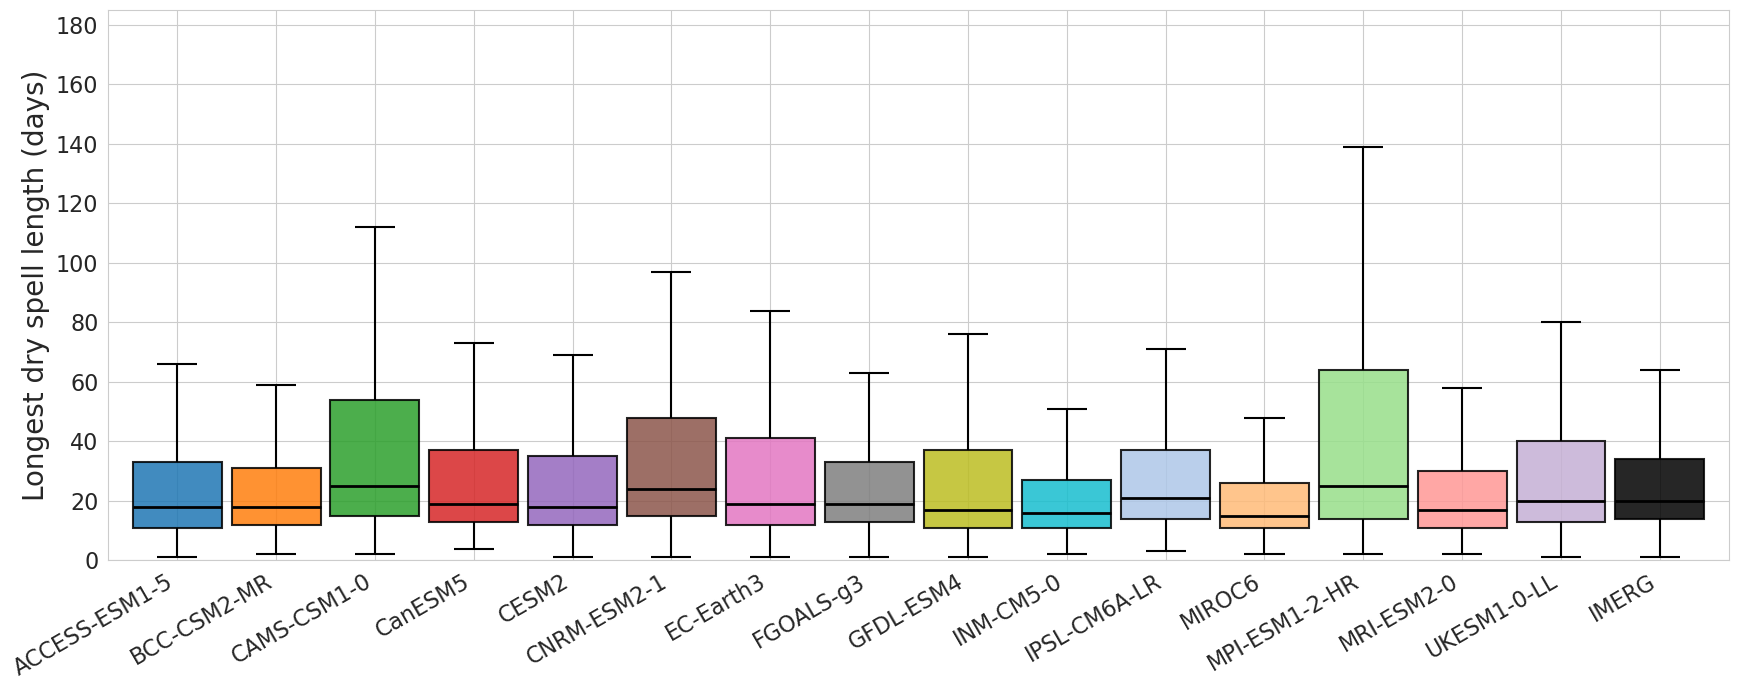

In [8]:
# ── plot (same style as the original box plot) ────────────────────────────────
sns.set_style("whitegrid")
n   = len(stats)
fig, ax = plt.subplots(figsize=(max(14, 1.1 * n), 7))
pos = np.arange(1, n + 1)
bw  = 0.45

for p, s, c in zip(pos, stats, colors):
    # IQR box
    ax.add_patch(mpatches.FancyBboxPatch(
        (p - bw, s['q25']), 2 * bw, s['q75'] - s['q25'],
        boxstyle="square,pad=0", linewidth=1.5,
        edgecolor='k', facecolor=c, alpha=0.85, zorder=3))
    # median line
    ax.hlines(s['q50'], p - bw, p + bw, colors='k', linewidth=2.0, zorder=4)
    # whiskers and caps
    ax.vlines(p, s['lo'],  s['q25'], colors='k', linewidth=1.5, zorder=2)
    ax.vlines(p, s['q75'], s['hi'],  colors='k', linewidth=1.5, zorder=2)
    cap_hw = bw * 0.45
    ax.hlines(s['lo'], p - cap_hw, p + cap_hw, colors='k', linewidth=1.5, zorder=2)
    ax.hlines(s['hi'], p - cap_hw, p + cap_hw, colors='k', linewidth=1.5, zorder=2)

ax.set_xlim(0.3, n + 0.7)
ax.set_ylim(0, 185)
ax.set_xticks(pos)
ax.set_xticklabels(labels, rotation=30, ha='right', fontsize=16)
ax.set_ylabel('Longest dry spell length (days)', fontsize=20)
ax.set_yticks(np.arange(0, 190, 20))
ax.tick_params(axis='y', labelsize=16)
#if any(d['fallback'] for d in cmip.values()):
#    ax.text(0.995, 0.98, f'* land mask interpolated from {FALLBACK_MASK_MODEL};  (n) = members',
#            transform=ax.transAxes, ha='right', va='top', fontsize=12)

plt.tight_layout()
os.makedirs(os.path.dirname(OUT_FILE), exist_ok=True)
plt.savefig(OUT_FILE, format='pdf', bbox_inches='tight')
plt.show()